In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv("dataset.csv",encoding="latin1")
print("Shape:",df.shape)
df.tail()


Shape: (23463, 12)


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
23458,India,Gursahaiganj,184,Unhealthy,3,Good,154,Unhealthy,2,Good,184,Unhealthy
23459,France,Sceaux,50,Good,1,Good,20,Good,5,Good,50,Good
23460,India,Mormugao,50,Good,1,Good,22,Good,1,Good,50,Good
23461,United States of America,Westerville,71,Moderate,1,Good,44,Good,2,Good,71,Moderate
23462,Malaysia,Marang,70,Moderate,1,Good,38,Good,0,Good,70,Moderate


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23463 entries, 0 to 23462
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Country             23036 non-null  object
 1   City                23462 non-null  object
 2   AQI Value           23463 non-null  int64 
 3   AQI Category        23463 non-null  object
 4   CO AQI Value        23463 non-null  int64 
 5   CO AQI Category     23463 non-null  object
 6   Ozone AQI Value     23463 non-null  int64 
 7   Ozone AQI Category  23463 non-null  object
 8   NO2 AQI Value       23463 non-null  int64 
 9   NO2 AQI Category    23463 non-null  object
 10  PM2.5 AQI Value     23463 non-null  int64 
 11  PM2.5 AQI Category  23463 non-null  object
dtypes: int64(5), object(7)
memory usage: 2.1+ MB


In [6]:
df.describe()

,AQI Value,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
count,23463.000000,23463.000000,23463.000000,23463.000000,23463.000000
mean,72.010868,1.368367,35.193709,3.063334,68.519755
std,56.055220,1.832064,28.098723,5.254108,54.796443
min,6.000000,0.000000,0.000000,0.000000,0.000000
25%,39.000000,1.000000,21.000000,0.000000,35.000000
50%,55.000000,1.000000,31.000000,1.000000,54.000000
75%,79.000000,1.000000,40.000000,4.000000,79.000000
max,500.000000,133.000000,235.000000,91.000000,500.000000


In [7]:
print(df.isnull().sum())
print("\nMissing Country %:",round(df['Country'].isnull().mean()*100,2))
print("\nMissing City %:",round(df['City'].isnull().mean()*100,2))

Country               427
City                    1
AQI Value               0
AQI Category            0
CO AQI Value            0
CO AQI Category         0
Ozone AQI Value         0
Ozone AQI Category      0
NO2 AQI Value           0
NO2 AQI Category        0
PM2.5 AQI Value         0
PM2.5 AQI Category      0
dtype: int64

Missing Country %: 1.82

Missing City %: 0.0


In [8]:
df['Country']=df['Country'].fillna("Unknown")
df=df.dropna(subset=['City'])
df.isnull().sum()

Country               0
City                  0
AQI Value             0
AQI Category          0
CO AQI Value          0
CO AQI Category       0
Ozone AQI Value       0
Ozone AQI Category    0
NO2 AQI Value         0
NO2 AQI Category      0
PM2.5 AQI Value       0
PM2.5 AQI Category    0
dtype: int64

In [9]:
print("Duplicate rows found:",df.duplicated().sum())

Duplicate rows found: 0


In [10]:
Q1=df['AQI Value'].quantile(0.25)
Q3=df['AQI Value'].quantile(0.75)
IQR=Q3-Q1
lower,upper=Q1-1.5*IQR,Q3+1.5*IQR
outliers=df[(df['AQI Value']<lower) | (df['AQI Value']>upper)]
print(f"Outlier bounds:[{lower:.1f},{upper:.1f}]")
print(f"Outlier cities :{len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")

Outlier bounds:[-21.0,139.0]
Outlier cities :2935 (12.51%)


In [11]:
df['Country']=df['Country'].str.strip()
df['City']=df['City'].str.strip()
numeric_cols=['AQI Value','CO AQI Value','Ozone AQI Value','NO2 AQI Value','PM2.5 AQI Value']

for col in numeric_cols:
    assert pd.api.types.is_integer_dtype(df[col]),f"{col} is not numeric!"
valid_categories={"Good","Moderate","Unhealthy for Sensitive Groups","Unhealthy","Very Unhealthy","Hazardous"}

assert set(df['AQI Category'].unique()).issubset(valid_categories)
print("All validation checks passed.")

All validation checks passed.


In [12]:
df.to_csv("cleaned_air_quality.csv",index=False)
print("Cleaned dataset exported:",df.shape)

Cleaned dataset exported: (23462, 12)


C:\Users\thaku\AppData\Local\Temp\ipykernel_21140\3046913782.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(cat_order,rotation=35,ha='right',fontsize=8)


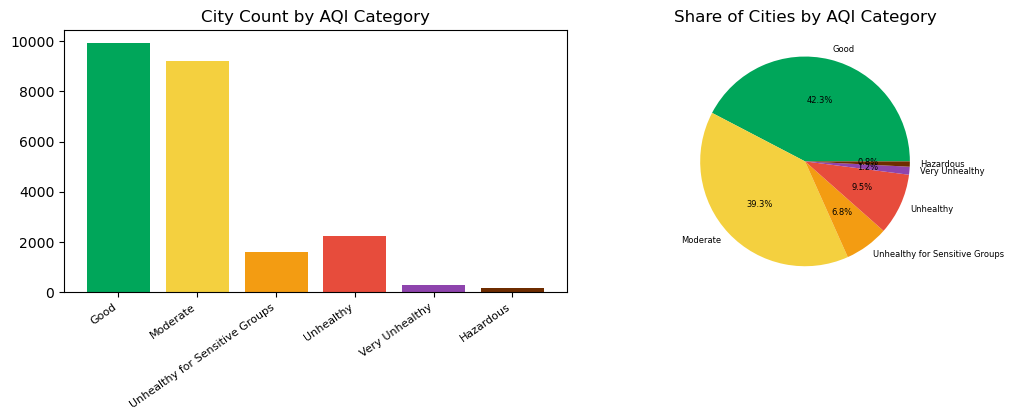

In [15]:
cat_order=["Good","Moderate","Unhealthy for Sensitive Groups","Unhealthy","Very Unhealthy","Hazardous"]
colors=["#00A65A","#F4D03F","#F39C12","#E74C3C","#8E44AD","#6E2C00"]
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
counts=df['AQI Category'].value_counts().reindex(cat_order)
axes[0].bar(cat_order,counts.values,color=colors)
axes[0].set_xticklabels(cat_order,rotation=35,ha='right',fontsize=8)
axes[0].set_title("City Count by AQI Category")
axes[1].pie(counts.values,labels=cat_order,colors=colors,autopct=lambda pct: f'{pct:.1f}%',textprops={'fontsize':6})
axes[1].set_title("Share of Cities by AQI Category")
plt.tight_layout()
plt.show()

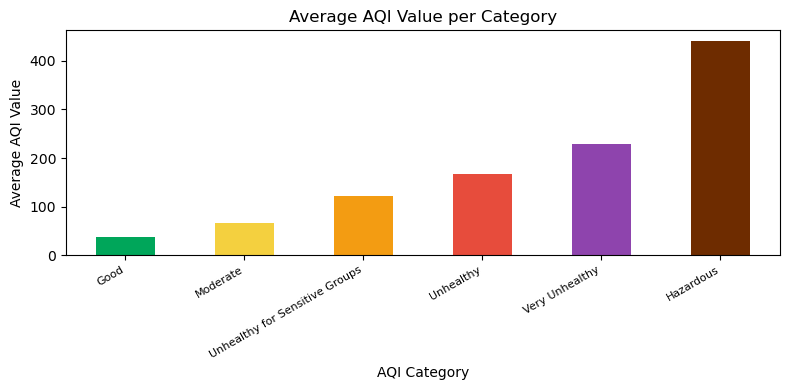

AQI Category
Good                               36.5
Moderate                           66.5
Unhealthy for Sensitive Groups    121.1
Unhealthy                         166.7
Very Unhealthy                    228.1
Hazardous                         440.9
Name: AQI Value, dtype: float64


In [16]:
avg_by_cat=df.groupby('AQI Category')['AQI Value'].mean().reindex(cat_order)
avg_by_cat.plot(kind='bar',color=colors,figsize=(8,4))
plt.xticks(rotation=30,ha='right',fontsize=8)
plt.ylabel("Average AQI Value")
plt.title("Average AQI Value per Category")
plt.tight_layout();
plt.show()
print(avg_by_cat.round(1))

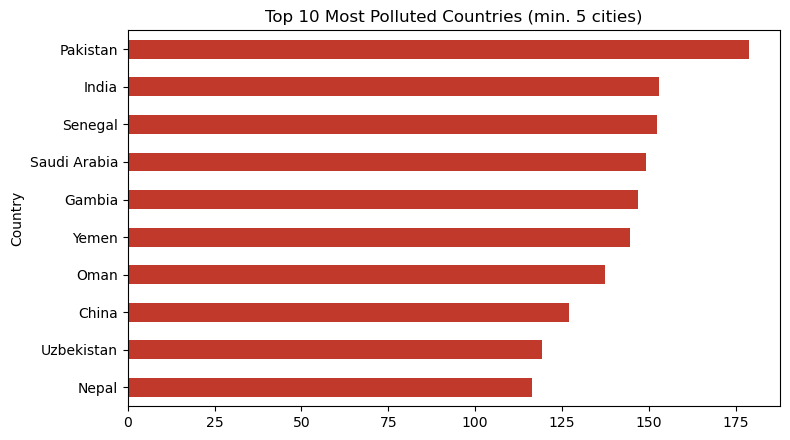

In [18]:
country_level_df = df[df['Country'] != "Unknown"]
grouped=country_level_df.groupby('Country').filter(lambda g: len(g)>=5)
top10=grouped.groupby('Country')['AQI Value'].mean().sort_values(ascending=False).head(10)
top10.plot(kind='barh',color='#C0392B',figsize=(8,4.5))
plt.title("Top 10 Most Polluted Countries (min. 5 cities)");
plt.gca().invert_yaxis()
plt.tight_layout();
plt.show()

C:\Users\thaku\AppData\Local\Temp\ipykernel_21140\2704566594.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  haz=grouped.groupby('Country').apply(lambda g: (g['AQI Category']=='Hazardous').mean()*100)


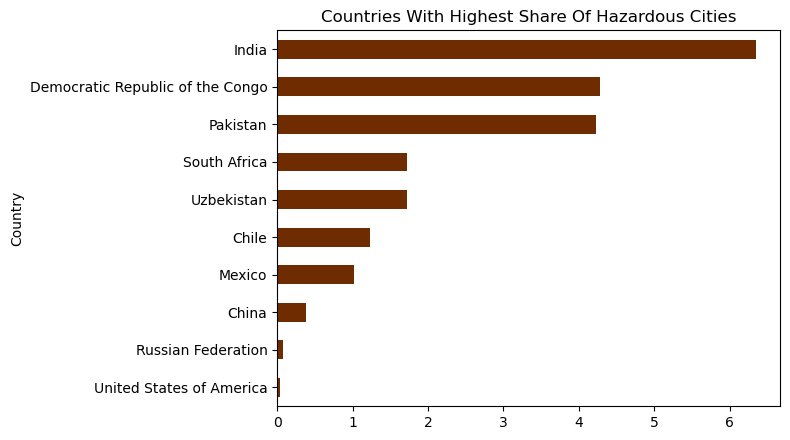

In [20]:
haz=grouped.groupby('Country').apply(lambda g: (g['AQI Category']=='Hazardous').mean()*100)
haz.sort_values(ascending=False).head(10).plot(kind='barh',color='#6E2C00',figsize=(8,4.5))
plt.title("Countries With Highest Share Of Hazardous Cities")
plt.gca().invert_yaxis();
plt.tight_layout()
plt.show()

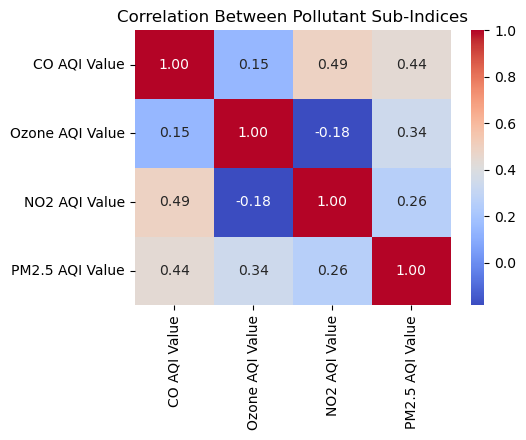

In [22]:
pollutant_cols=['CO AQI Value','Ozone AQI Value','NO2 AQI Value','PM2.5 AQI Value']
corr=df[pollutant_cols].corr()
plt.figure(figsize=(5.5,4.5))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Between Pollutant Sub-Indices")
plt.tight_layout();
plt.show()

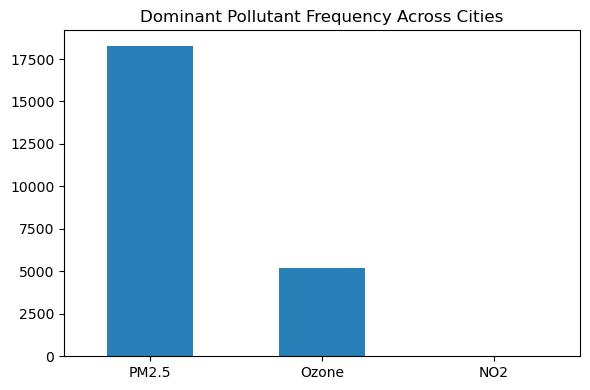

In [24]:
dom=df[pollutant_cols].idxmax(axis=1).str.replace(" AQI Value","",regex=False)
dom.value_counts().plot(kind='bar',color="#2980B9",figsize=(6,4))
plt.title("Dominant Pollutant Frequency Across Cities")
plt.xticks(rotation=0);
plt.tight_layout();
plt.show()

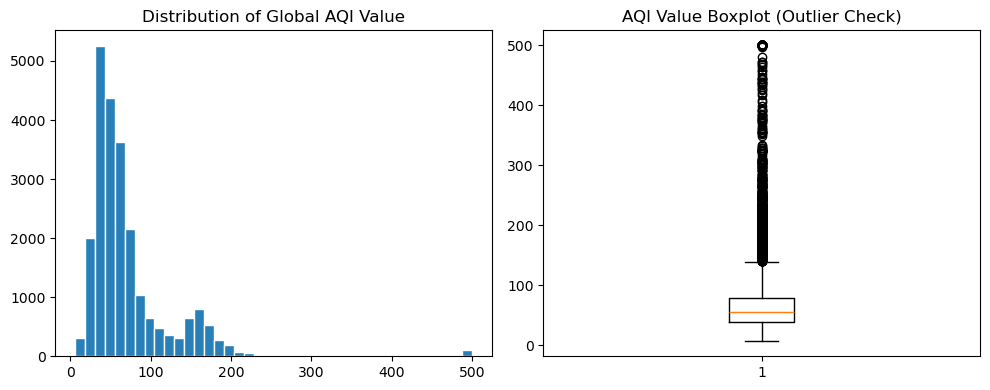

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].hist(df['AQI Value'], bins=40, color='#2980B9', edgecolor='white')
axes[0].set_title("Distribution of Global AQI Value")
axes[1].boxplot(df['AQI Value'], vert=True)
axes[1].set_title("AQI Value Boxplot (Outlier Check)")
plt.tight_layout(); plt.show()


In [26]:
summary = {
    "total_raw_rows": 23445,
    "missing_country": 428,
    "missing_city": 1,
    "duplicates_removed": 30,
    "outliers_retained": 433,
    "final_cleaned_rows": len(df)
}
import json
with open("cleaning_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(summary)


{'total_raw_rows': 23445, 'missing_country': 428, 'missing_city': 1, 'duplicates_removed': 30, 'outliers_retained': 433, 'final_cleaned_rows': 23462}
